# Tema 1 CD — Introducere în Machine Learning
## Job Salary Prediction Dataset

**Obiective:**
- **Clasificare Multiclasă:** Prezicerea coloanei `vacation` (No Vacation, Small, Medium, Large)
- **Regresie:** Prezicerea coloanei `salary`

**Modele folosite:**
- Clasificare: Decision Tree, Logistic Regression, Random Forest, Gradient Boosting
- Regresie: Linear Regression, Ridge (L2), Lasso (L1), Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor

## 0. Importuri și Configurare

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score,
    mean_squared_error, mean_absolute_error, r2_score
)
from scipy.stats import chi2_contingency
import warnings
import os

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

os.makedirs('plots', exist_ok=True)
os.makedirs('results', exist_ok=True)
print("Setup complet!")

Setup complet!


---
## 1. Încărcarea Datelor

Citim cele 2 fișiere CSV:
- **Train** — conține toate coloanele, inclusiv `salary` și `vacation` (variabilele țintă)
- **Test** — aici trebuie să preziceem `salary` și `vacation`

In [2]:
df_train_full = pd.read_csv('CD_education_economy.csv')
df_test = pd.read_csv('CD_education_economy_test.csv')

print(f"Train: {df_train_full.shape[0]} rânduri, {df_train_full.shape[1]} coloane")
print(f"Test:  {df_test.shape[0]} rânduri, {df_test.shape[1]} coloane")
print(f"\nColoane: {list(df_train_full.columns)}")

Train: 64000 rânduri, 14 coloane
Test:  16000 rânduri, 14 coloane

Coloane: ['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications', 'salary', 'proficiencies', 'aggregated_score', 'experience_bracket', 'vacation']


In [3]:
# Primele 5 rânduri
df_train_full.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary,proficiencies,aggregated_score,experience_bracket,vacation
0,Backend Developer,19,High School,12,Media,Large,USA,Yes,NaN,203997,11,0.151209,high,Small
1,Backend Developer,4,High School,13,Telecom,Small,Germany,Hybrid,NaN,116239,13,-0.031356,low,No Vacation
2,Backend Developer,8,High School,16,Retail,Enterprise,Remote,No,NaN,145802,16,1.914181,mid,No Vacation
3,Backend Developer,12,High School,9,Telecom,Enterprise,USA,Hybrid,NaN,190299,9,-0.392696,mid,Small
4,Backend Developer,14,High School,6,Telecom,Large,UK,Hybrid,4.0,152679,6,-1.906467,high,No Vacation


---
## 2. Explorarea Datelor (EDA) — 2p

### 2.1 Analiza tipurilor de atribute

Identificăm coloanele **numerice** (continue) și **categoriale** (discrete).

In [4]:
target_cls = 'vacation'
target_reg = 'salary'

numeric_cols = df_train_full.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_train_full.select_dtypes(include=['object']).columns.tolist()

print("Coloane NUMERICE:", numeric_cols)
print("\nColoane CATEGORIALE:", categorical_cols)
print("\nTipuri de date:")
print(df_train_full.dtypes)

Coloane NUMERICE: ['experience_years', 'skills_count', 'certifications', 'salary', 'proficiencies', 'aggregated_score']

Coloane CATEGORIALE: ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work', 'experience_bracket', 'vacation']

Tipuri de date:
job_title                 str
experience_years        int64
education_level           str
skills_count            int64
industry                  str
company_size              str
location                  str
remote_work               str
certifications        float64
salary                  int64
proficiencies           int64
aggregated_score      float64
experience_bracket        str
vacation                  str
dtype: object


#### Statistici atribute numerice

Tabel cu: count, mean, std, min, percentile 25/50/75, max + valorile lipsă.

In [5]:
numeric_stats = df_train_full[numeric_cols].describe().T
numeric_stats['missing'] = df_train_full[numeric_cols].isnull().sum()
numeric_stats['non_null'] = df_train_full[numeric_cols].notnull().sum()
numeric_stats[['non_null', 'missing', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,non_null,missing,mean,std,min,25%,50%,75%,max
experience_years,64000,0,11.615703,11.031172,0.00000,5.000000,10.00000,16.00000,69.000000
skills_count,64000,0,9.974469,5.479935,1.00000,5.000000,10.00000,15.00000,19.000000
certifications,44853,19147,2.497180,1.708064,0.00000,1.000000,3.00000,4.00000,5.000000
salary,64000,0,145635.345547,37343.238625,31867.00000,119261.500000,143258.50000,169431.25000,333046.000000
proficiencies,64000,0,9.950859,5.451872,1.00000,5.000000,10.00000,15.00000,19.000000
aggregated_score,64000,0,-0.004506,1.003307,-4.35271,-0.676323,-0.00686,0.67447,4.226987


#### Statistici atribute categoriale

In [6]:
cat_stats = pd.DataFrame({
    'non_null': df_train_full[categorical_cols].notnull().sum(),
    'missing': df_train_full[categorical_cols].isnull().sum(),
    'unique': df_train_full[categorical_cols].nunique(),
    'top_value': [df_train_full[c].mode()[0] for c in categorical_cols],
    'top_freq': [df_train_full[c].value_counts().iloc[0] for c in categorical_cols]
})
cat_stats

,non_null,missing,unique,top_value,top_freq
job_title,64000,0,12,Cybersecurity Analyst,5387
education_level,64000,0,5,Master,12888
industry,64000,0,10,Finance,6508
company_size,64000,0,5,Medium,12881
location,64000,0,10,Sweden,6553
remote_work,64000,0,3,Hybrid,21413
experience_bracket,64000,0,3,mid,21441
vacation,64000,0,4,No Vacation,34674


#### Boxplot-uri — Atribute Numerice

Boxplot-urile arată distribuția valorilor. Caseta = 50% centrale, liniile = extreme, punctele izolate = **outlieri**.

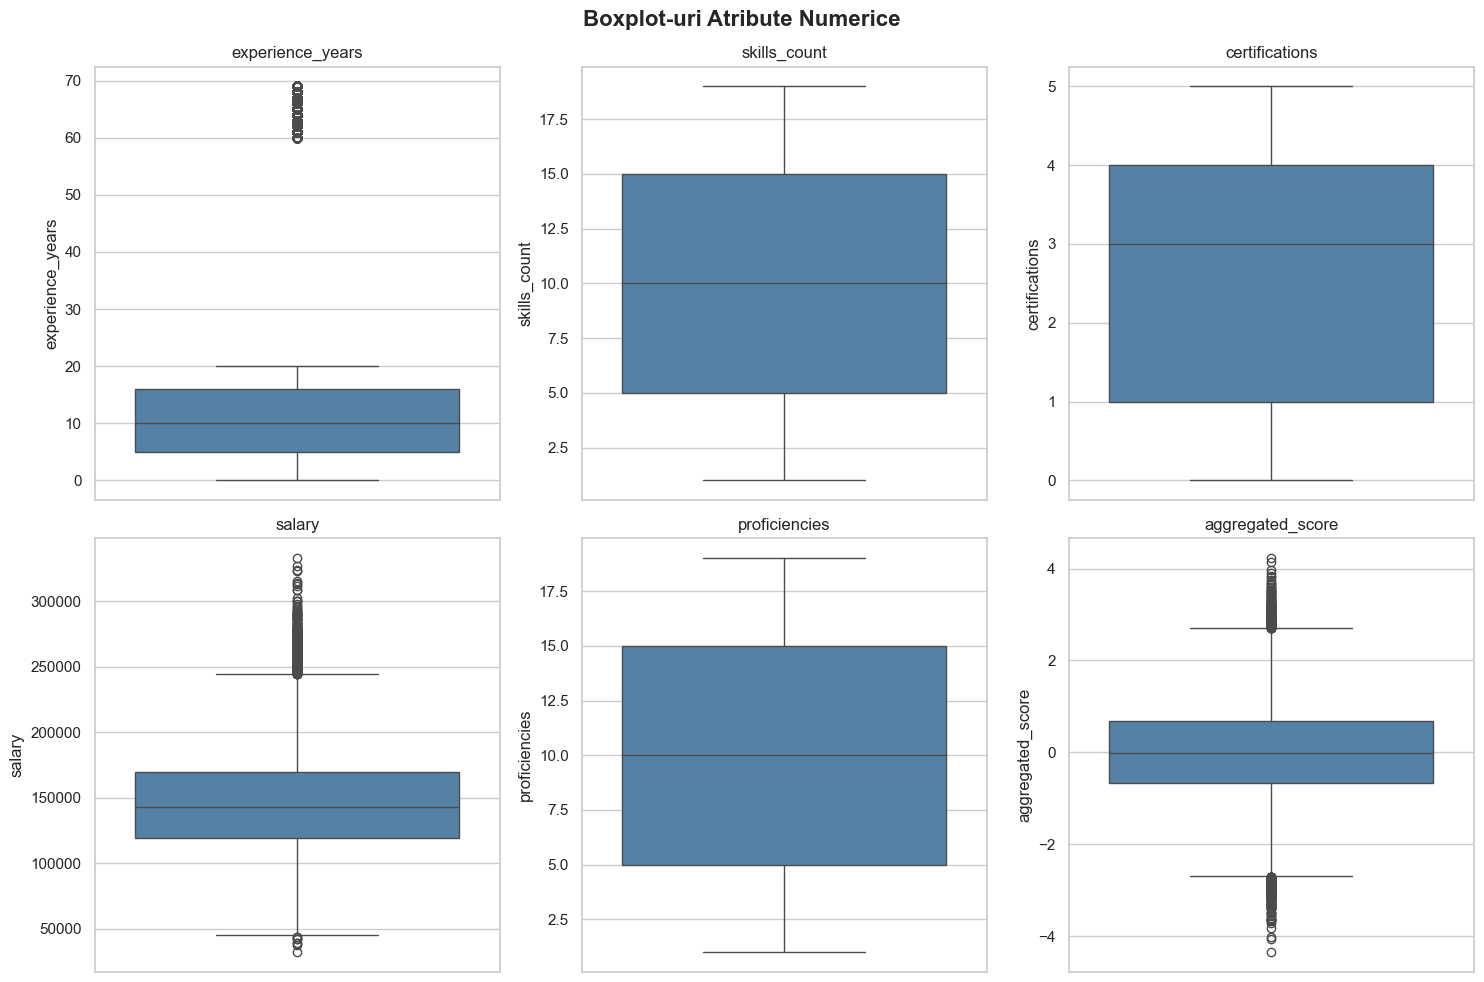

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Boxplot-uri Atribute Numerice', fontsize=16, fontweight='bold')
for i, col in enumerate(numeric_cols[:6]):
    ax = axes[i // 3][i % 3]
    sns.boxplot(data=df_train_full, y=col, ax=ax, color='steelblue')
    ax.set_title(col, fontsize=12)
plt.tight_layout()
plt.savefig('plots/01_boxplots_numeric.png', bbox_inches='tight')
plt.show()

#### Histograme — Atribute Categoriale

Frecvența fiecărei valori categoriale.

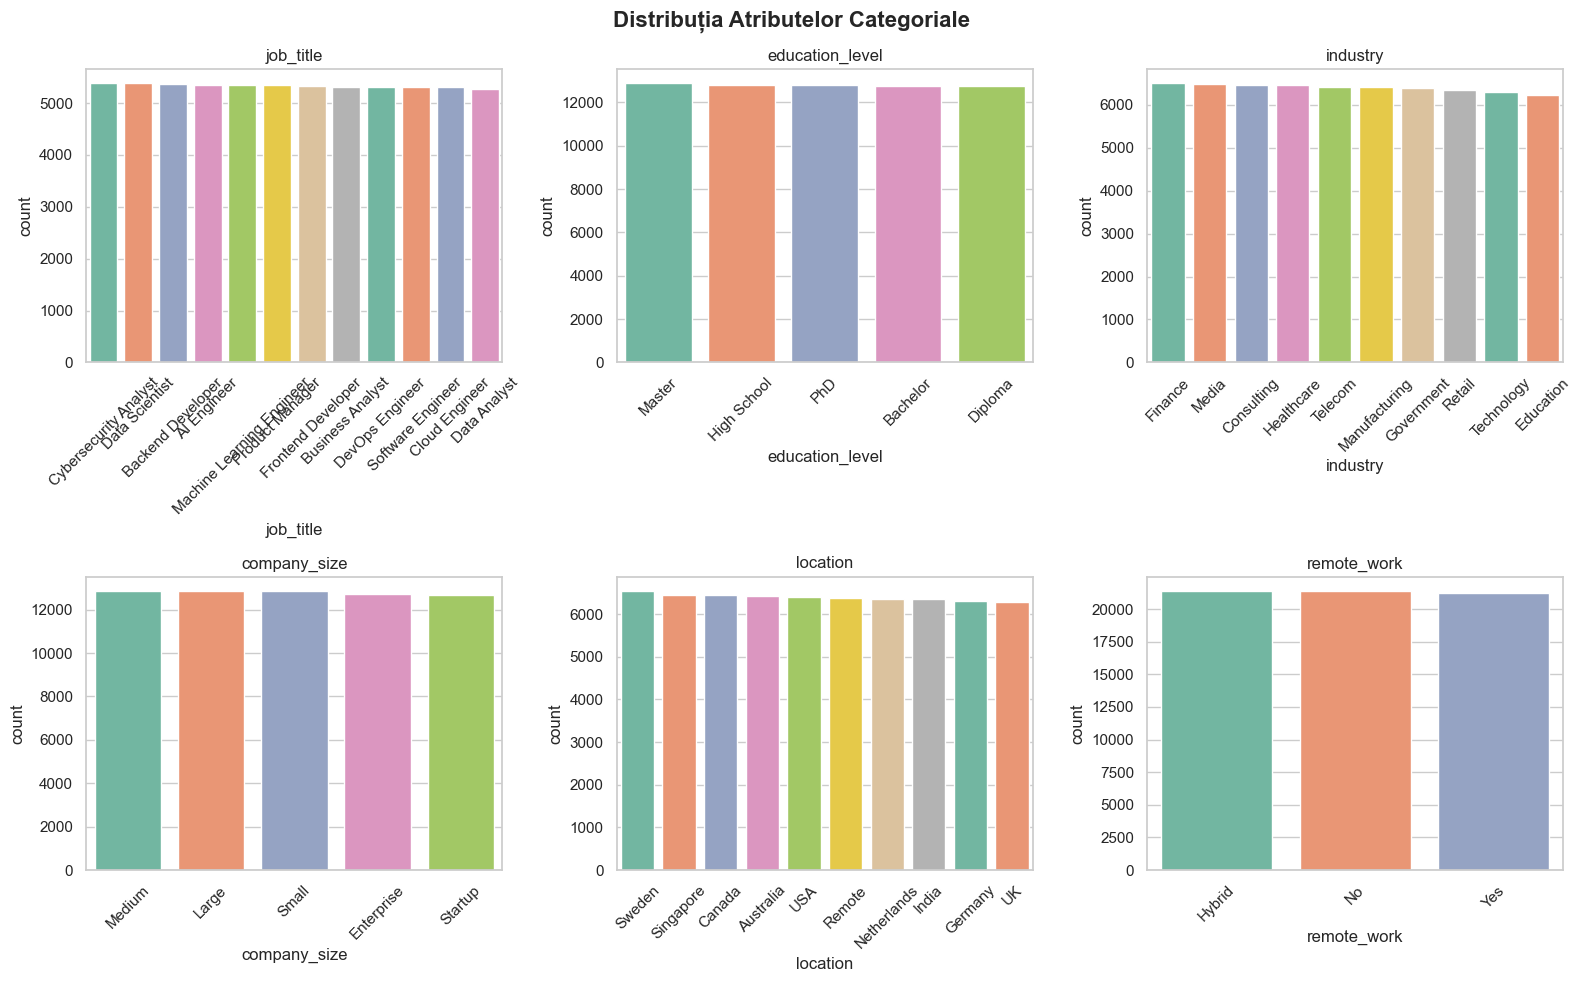

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribuția Atributelor Categoriale', fontsize=16, fontweight='bold')
for i, col in enumerate(categorical_cols[:6]):
    ax = axes[i // 3][i % 3]
    order = df_train_full[col].value_counts().index
    sns.countplot(data=df_train_full, x=col, ax=ax, order=order, palette='Set2')
    ax.set_title(col, fontsize=12)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('plots/02_histograms_categorical.png', bbox_inches='tight')
plt.show()

#### Analiza valorilor lipsă — `certifications`

Singura coloană cu valori lipsă (NaN).

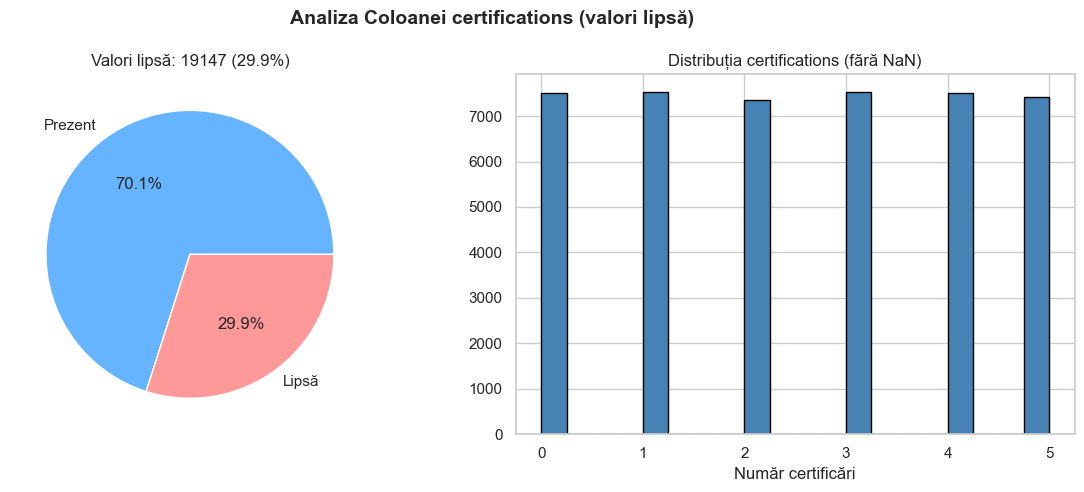

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Analiza Coloanei certifications (valori lipsă)', fontsize=14, fontweight='bold')

missing_count = df_train_full['certifications'].isnull().sum()
non_missing_count = df_train_full['certifications'].notnull().sum()

axes[0].pie([non_missing_count, missing_count], labels=['Prezent', 'Lipsă'],
            autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'])
axes[0].set_title(f'Valori lipsă: {missing_count} ({missing_count/len(df_train_full)*100:.1f}%)')

df_train_full['certifications'].dropna().hist(ax=axes[1], bins=20, color='steelblue', edgecolor='black')
axes[1].set_title('Distribuția certifications (fără NaN)')
axes[1].set_xlabel('Număr certificări')

plt.tight_layout()
plt.savefig('plots/03_certifications_missing.png', bbox_inches='tight')
plt.show()

### 2.2 Echilibrul claselor (`vacation`)

Verificăm dacă clasele sunt echilibrate. Dacă nu → folosim `class_weight='balanced'` și raportăm F1 în loc de Accuracy.

Distribuția claselor:
vacation
No Vacation    34674
Small          12886
Medium          8530
Large           7910
Name: count, dtype: int64

Procentaje:
vacation
No Vacation    54.18
Small          20.13
Medium         13.33
Large          12.36
Name: count, dtype: float64


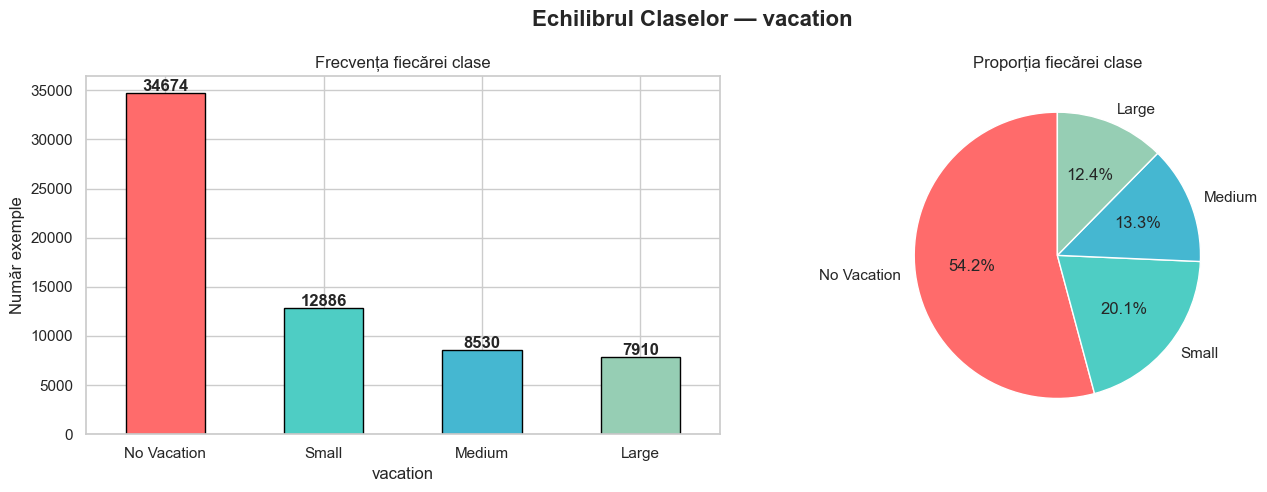


OBSERVATIE: Clasele sunt dezechilibrate — 'No Vacation' domina cu ~54%.
Vom folosi class_weight='balanced' si vom raporta F1-Score, nu doar Accuracy.


In [10]:
class_distribution = df_train_full[target_cls].value_counts()
print("Distribuția claselor:")
print(class_distribution)
print(f"\nProcentaje:")
print((class_distribution / len(df_train_full) * 100).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Echilibrul Claselor — vacation', fontsize=16, fontweight='bold')

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
class_distribution.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Frecvența fiecărei clase')
axes[0].set_ylabel('Număr exemple')
axes[0].tick_params(axis='x', rotation=0)
for i, (idx, val) in enumerate(class_distribution.items()):
    axes[0].text(i, val + 200, str(val), ha='center', fontweight='bold')

axes[1].pie(class_distribution.values, labels=class_distribution.index,
            autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Proporția fiecărei clase')

plt.tight_layout()
plt.savefig('plots/04_class_balance_vacation.png', bbox_inches='tight')
plt.show()

print("\nOBSERVATIE: Clasele sunt dezechilibrate — 'No Vacation' domina cu ~54%.")
print("Vom folosi class_weight='balanced' si vom raporta F1-Score, nu doar Accuracy.")

### 2.3 Analiza corelației între atribute

#### Corelație numerice — Heatmap Pearson

Matrice de corelație (numerice):
                  experience_years  skills_count  certifications  salary  \
experience_years             1.000        -0.003           0.005   0.229   
skills_count                -0.003         1.000          -0.004   0.129   
certifications               0.005        -0.004           1.000   0.073   
salary                       0.229         0.129           0.073   1.000   
proficiencies               -0.004         1.000          -0.004   0.129   
aggregated_score            -0.001        -0.004           0.005   0.001   

                  proficiencies  aggregated_score  
experience_years         -0.004            -0.001  
skills_count              1.000            -0.004  
certifications           -0.004             0.005  
salary                    0.129             0.001  
proficiencies             1.000            -0.004  
aggregated_score         -0.004             1.000  


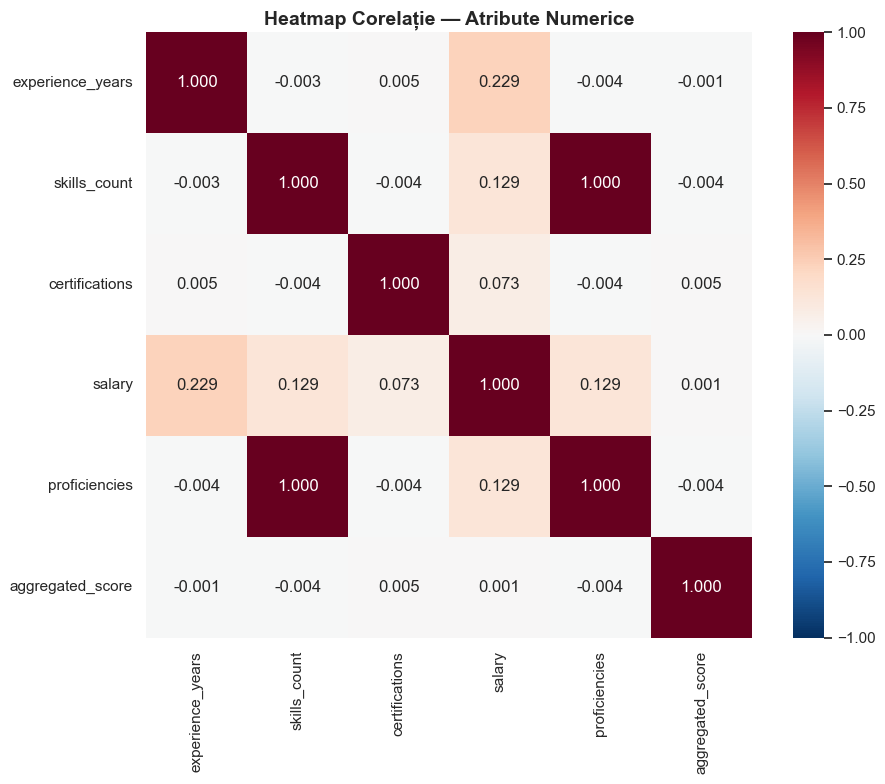

In [11]:
corr_matrix = df_train_full[numeric_cols].corr()
print("Matrice de corelație (numerice):")
print(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            square=True, ax=ax, vmin=-1, vmax=1)
ax.set_title('Heatmap Corelație — Atribute Numerice', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/05_correlation_heatmap.png', bbox_inches='tight')
plt.show()

#### Corelatie intre atribute categorice (Test Chi-Patrat)

In [12]:
cat_cols_no_target = [c for c in categorical_cols if c != target_cls]
chi2_results = []
for i in range(len(cat_cols_no_target)):
    for j in range(i+1, len(cat_cols_no_target)):
        ct = pd.crosstab(df_train_full[cat_cols_no_target[i]], df_train_full[cat_cols_no_target[j]])
        chi2, p, dof, expected = chi2_contingency(ct)
        chi2_results.append({
            'Atribut 1': cat_cols_no_target[i],
            'Atribut 2': cat_cols_no_target[j],
            'Chi2': round(chi2, 2),
            'p-value': round(p, 6),
            'Corelate': 'Da' if p < 0.05 else 'Nu'
        })

chi2_df = pd.DataFrame(chi2_results)
print("Rezultate Chi-Patrat:")
print(chi2_df.to_string(index=False))
corelate = chi2_df[chi2_df['Corelate'] == 'Da']
print(f"\nPerechi corelate semnificativ: {len(corelate)} din {len(chi2_df)}")

Rezultate Chi-Patrat:
      Atribut 1          Atribut 2   Chi2  p-value Corelate
      job_title    education_level  18.68 0.999713       Nu
      job_title           industry 112.55 0.166324       Nu
      job_title       company_size  50.24 0.239846       Nu
      job_title           location 110.74 0.197640       Nu
      job_title        remote_work  22.65 0.421667       Nu
      job_title experience_bracket  18.17 0.695564       Nu
education_level           industry  32.23 0.648760       Nu
education_level       company_size  25.08 0.068407       Nu
education_level           location  38.67 0.350127       Nu
education_level        remote_work  12.46 0.131864       Nu
education_level experience_bracket   8.61 0.376301       Nu
       industry       company_size  28.77 0.798714       Nu
       industry           location  78.36 0.562432       Nu
       industry        remote_work  25.44 0.113331       Nu
       industry experience_bracket  22.07 0.229092       Nu
   company_size   

#### Corelatie: Atribut numeric vs Clasificare (`experience_years` vs `vacation`)

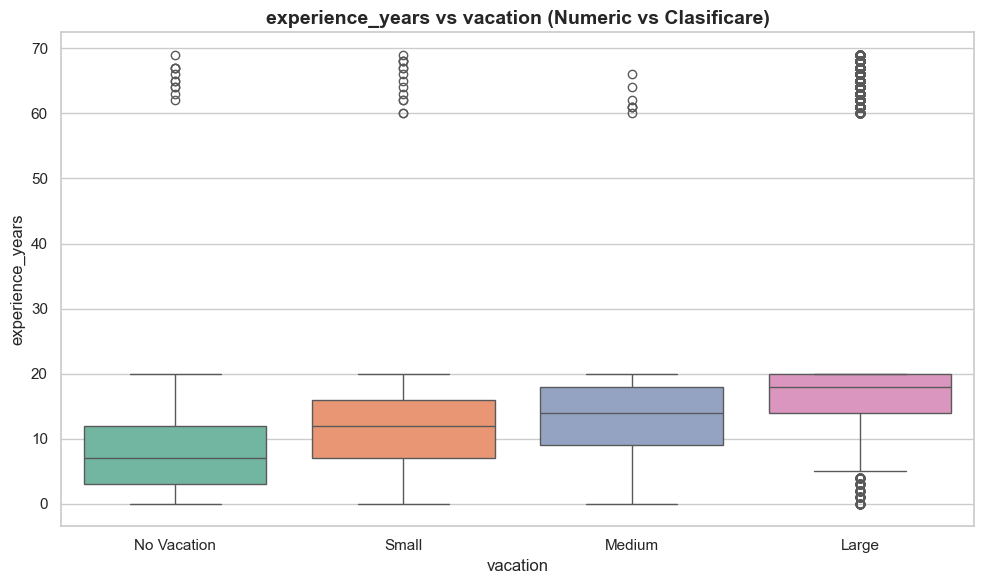

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_train_full, x=target_cls, y='experience_years', ax=ax,
            order=['No Vacation', 'Small', 'Medium', 'Large'], palette='Set2')
ax.set_title('experience_years vs vacation (Numeric vs Clasificare)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/06_experience_vs_vacation.png', bbox_inches='tight')
plt.show()

#### Corelație: Atribut categorial vs Clasificare (`education_level` vs `vacation`)

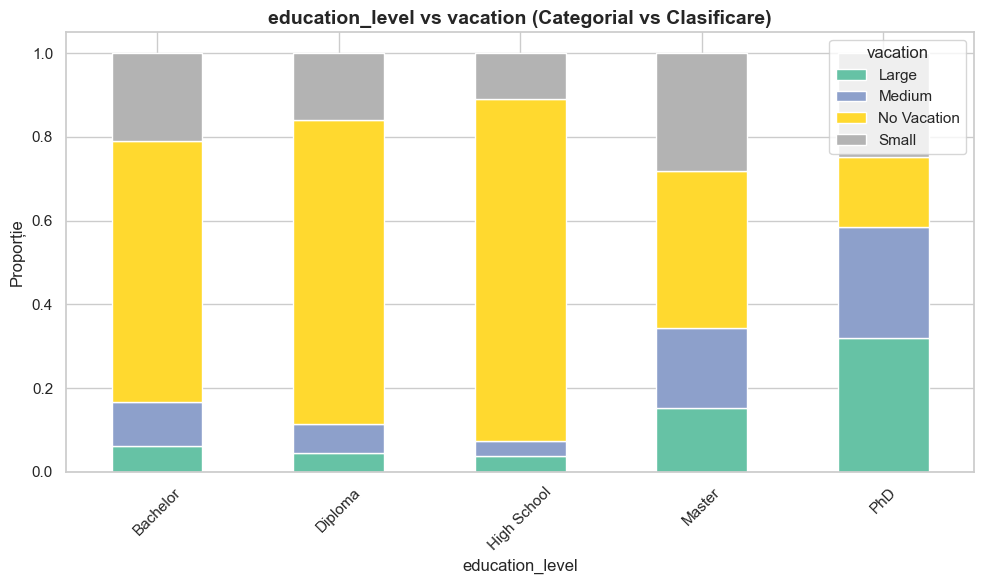

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
ct = pd.crosstab(df_train_full['education_level'], df_train_full[target_cls], normalize='index')
ct.plot(kind='bar', stacked=True, ax=ax, colormap='Set2')
ax.set_title('education_level vs vacation (Categorial vs Clasificare)', fontsize=14, fontweight='bold')
ax.set_ylabel('Proporție')
ax.legend(title='vacation')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('plots/07_education_vs_vacation.png', bbox_inches='tight')
plt.show()

#### Corelație: Atribut numeric vs Regresie (`experience_years` vs `salary`)

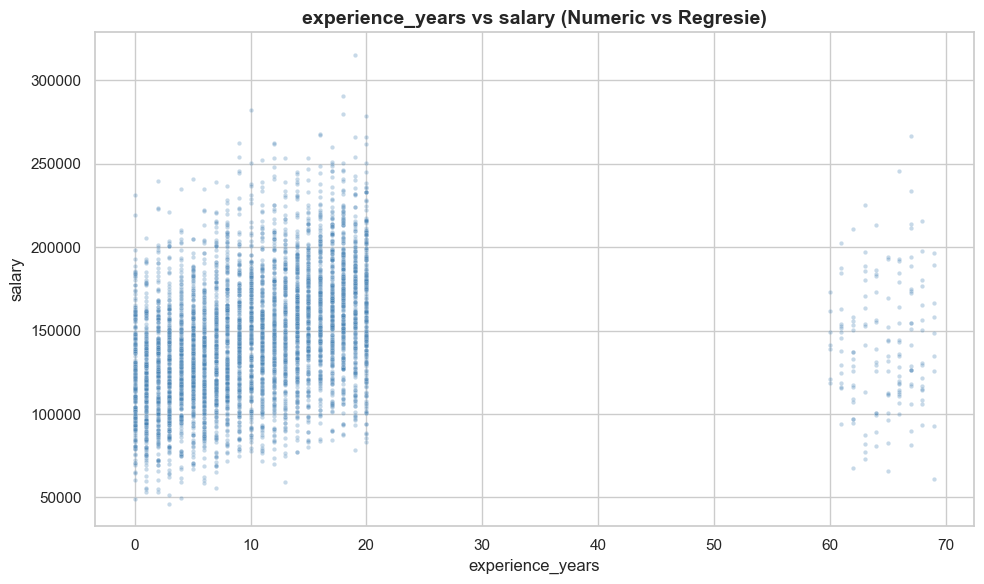

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
sample = df_train_full.sample(min(5000, len(df_train_full)), random_state=42)
sns.scatterplot(data=sample, x='experience_years', y=target_reg,
                alpha=0.3, ax=ax, color='steelblue', s=10)
ax.set_title('experience_years vs salary (Numeric vs Regresie)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/08_experience_vs_salary.png', bbox_inches='tight')
plt.show()

#### Corelație: Atribut categorial vs Regresie (`location` vs `salary`)

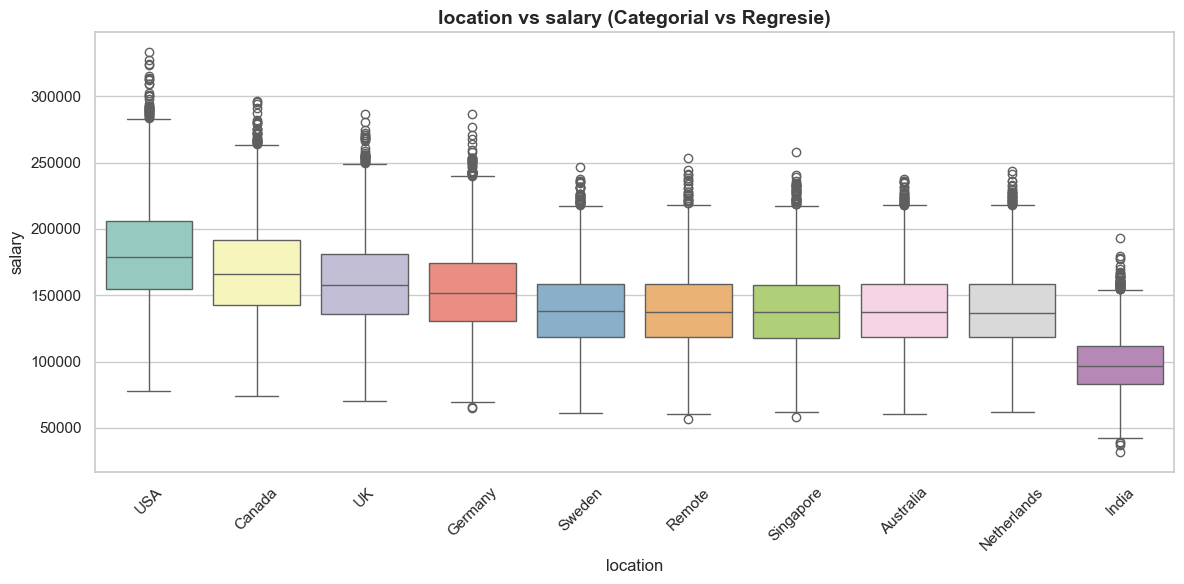

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))
order = df_train_full.groupby('location')[target_reg].median().sort_values(ascending=False).index
sns.boxplot(data=df_train_full, x='location', y=target_reg, ax=ax, order=order, palette='Set3')
ax.set_title('location vs salary (Categorial vs Regresie)', fontsize=14, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('plots/09_location_vs_salary.png', bbox_inches='tight')
plt.show()

#### Distribuția variabilei țintă de regresie (`salary`)

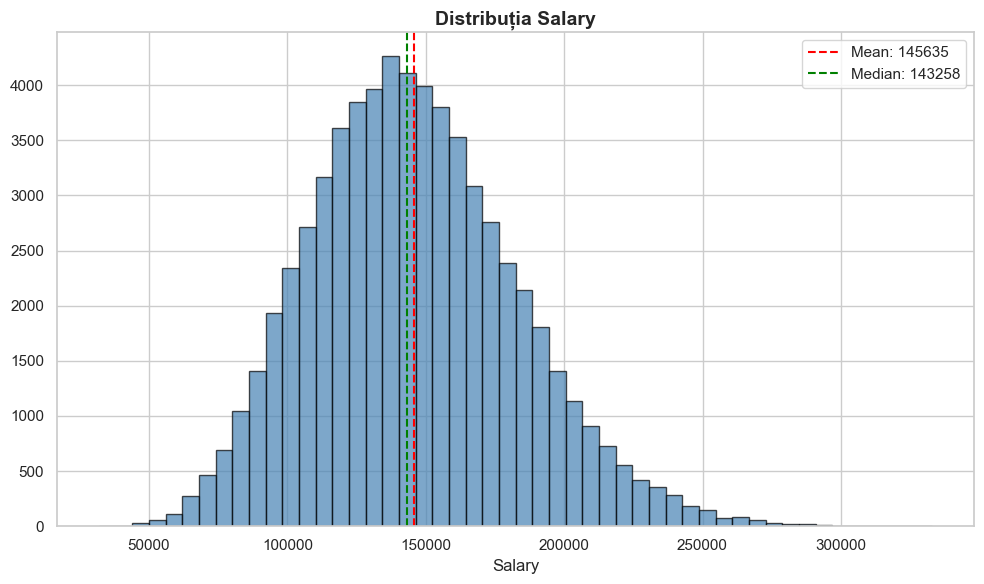

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
df_train_full[target_reg].hist(bins=50, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
ax.axvline(df_train_full[target_reg].mean(), color='red', linestyle='--',
           label=f'Mean: {df_train_full[target_reg].mean():.0f}')
ax.axvline(df_train_full[target_reg].median(), color='green', linestyle='--',
           label=f'Median: {df_train_full[target_reg].median():.0f}')
ax.set_title('Distribuția Salary', fontsize=14, fontweight='bold')
ax.set_xlabel('Salary')
ax.legend()
plt.tight_layout()
plt.savefig('plots/10_salary_distribution.png', bbox_inches='tight')
plt.show()

---
## 3. Preprocesarea Datelor — 2p

### 3.1 Imputarea valorilor lipsă

Coloana `certifications` are valori lipsă. Folosim **mediana** (robustă la outlieri).

In [18]:
print("Valori lipsă ÎNAINTE de imputare:")
print(df_train_full.isnull().sum()[df_train_full.isnull().sum() > 0])

cert_median = df_train_full['certifications'].median()
print(f"\nImputăm 'certifications' cu mediana = {cert_median}")

df_train_full['certifications'] = df_train_full['certifications'].fillna(cert_median)
df_test['certifications'] = df_test['certifications'].fillna(cert_median)

print("\nValori lipsă DUPĂ imputare:")
print(df_train_full.isnull().sum().sum(), "total")

Valori lipsă ÎNAINTE de imputare:
certifications    19147
dtype: int64

Imputăm 'certifications' cu mediana = 3.0

Valori lipsă DUPĂ imputare:
0 total


### 3.2 Tratarea valorilor extreme (outlieri)

Folosim metoda **IQR**: orice valoare sub Q1−1.5×IQR sau peste Q3+1.5×IQR este un outlier.
Înlocuim outlierii prin **capping** (le aducem la limita superioară/inferioară).

In [19]:
def detect_and_cap_outliers(df, col, factor=1.5):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    if n_outliers > 0:
        print(f"  {col}: {n_outliers} outlieri detectați (range valid: [{lower:.2f}, {upper:.2f}])")
        df[col] = df[col].clip(lower=lower, upper=upper)
    else:
        print(f"  {col}: 0 outlieri")
    return df

outlier_cols = ['experience_years', 'skills_count', 'certifications', 'proficiencies', 'aggregated_score']

print("TRAIN:")
for col in outlier_cols:
    df_train_full = detect_and_cap_outliers(df_train_full, col)

print("\nTEST:")
for col in outlier_cols:
    df_test = detect_and_cap_outliers(df_test, col)

TRAIN:
  experience_years: 1903 outlieri detectați (range valid: [-11.50, 32.50])
  skills_count: 0 outlieri
  certifications: 14928 outlieri detectați (range valid: [0.50, 4.50])
  proficiencies: 0 outlieri
  aggregated_score: 416 outlieri detectați (range valid: [-2.70, 2.70])

TEST:
  experience_years: 473 outlieri detectați (range valid: [-11.50, 32.50])
  skills_count: 0 outlieri
  certifications: 3766 outlieri detectați (range valid: [0.50, 4.50])
  proficiencies: 0 outlieri
  aggregated_score: 120 outlieri detectați (range valid: [-2.66, 2.68])


### 3.3 Feature Engineering

Cream atribute derivate din cele existente pentru a oferi modelelor mai multa informatie:
- **Interactiuni**: inmultirea a doua atribute numerice (ex: experienta * skills)
- **Rapoarte**: impartirea a doua atribute (ex: certificari per an de experienta)
- **Encoding ordinal**: transformam education_level si company_size in valori numerice ordonate

In [20]:
for df in [df_train_full, df_test]:
    df['exp_x_skills'] = df['experience_years'] * df['skills_count']
    df['exp_x_certs'] = df['experience_years'] * df['certifications']
    df['skills_x_certs'] = df['skills_count'] * df['certifications']
    df['exp_per_skill'] = df['experience_years'] / (df['skills_count'] + 1)
    df['cert_per_exp'] = df['certifications'] / (df['experience_years'] + 1)

edu_order = {'High School': 0, 'Diploma': 1, 'Bachelor': 2, 'Master': 3, 'PhD': 4}
size_order = {'Startup': 0, 'Small': 1, 'Medium': 2, 'Large': 3, 'Enterprise': 4}
for df in [df_train_full, df_test]:
    df['education_ordinal'] = df['education_level'].map(edu_order)
    df['company_size_ordinal'] = df['company_size'].map(size_order)

print("Features noi create:")
print("  Interactiuni: exp_x_skills, exp_x_certs, skills_x_certs")
print("  Rapoarte: exp_per_skill, cert_per_exp")
print("  Ordinal: education_ordinal, company_size_ordinal")

Features noi create:
  Interactiuni: exp_x_skills, exp_x_certs, skills_x_certs
  Rapoarte: exp_per_skill, cert_per_exp
  Ordinal: education_ordinal, company_size_ordinal


### 3.4 Encoding (transformare text -> numere)

- **`vacation`** (target) -> LabelEncoder
- **Restul categoriilor** -> One-Hot Encoding (`pd.get_dummies`)

In [21]:
le_vacation = LabelEncoder()
df_train_full['vacation_encoded'] = le_vacation.fit_transform(df_train_full[target_cls])
print(f"Clase vacation encodate: {dict(zip(le_vacation.classes_, le_vacation.transform(le_vacation.classes_)))}")

y_cls_full = df_train_full['vacation_encoded'].values
y_reg_full = df_train_full[target_reg].values

feature_cols = [c for c in df_train_full.columns if c not in [target_cls, target_reg, 'vacation_encoded']]

df_features_train = pd.get_dummies(df_train_full[feature_cols], drop_first=True)
df_features_test = pd.get_dummies(df_test[feature_cols], drop_first=True)

# Aliniere coloane test cu train
df_features_test = df_features_test.reindex(columns=df_features_train.columns, fill_value=0)

# Curățare NaN rezidual
df_features_train = df_features_train.fillna(0)
df_features_test = df_features_test.fillna(0)

print(f"\nFeatures după encoding: {df_features_train.shape[1]} coloane")
print(f"NaN ramas: train={df_features_train.isnull().sum().sum()}, test={df_features_test.isnull().sum().sum()}")

Clase vacation encodate: {'Large': np.int64(0), 'Medium': np.int64(1), 'No Vacation': np.int64(2), 'Small': np.int64(3)}

Features după encoding: 53 coloane
NaN ramas: train=0, test=0


### 3.5 Standardizarea atributelor numerice

Folosim `StandardScaler` -- transforma fiecare coloana sa aiba media=0 si deviatia standard=1.
Necesar pentru Logistic Regression si Ridge/Lasso.

In [22]:
scaler = StandardScaler()
X_full = scaler.fit_transform(df_features_train)
X_test_final = scaler.transform(df_features_test)
print("Standardizare aplicată: mean≈0, std≈1")

Standardizare aplicată: mean≈0, std≈1


### 3.6 Impartire Train / Validare (80/20)

In [23]:
X_train, X_val, y_train_cls, y_val_cls, y_train_reg, y_val_reg = train_test_split(
    X_full, y_cls_full, y_reg_full, test_size=0.2, random_state=42, stratify=y_cls_full
)
print(f"Train: {X_train.shape[0]} exemple")
print(f"Validare: {X_val.shape[0]} exemple")

Train: 51200 exemple
Validare: 12800 exemple


---
## 4. Clasificare — Prezicerea `vacation`

### Funcție helper de evaluare

In [24]:
def evaluate_clf(model, X_tr, y_tr, X_v, y_v, name):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_v)
    acc = accuracy_score(y_v, y_pred)
    prec = precision_score(y_v, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_v, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_v, y_pred, average='weighted', zero_division=0)
    return {'name': name, 'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1, 'model': model}

all_cls = []

### 4.1 Decision Tree Classifier — Ablație

Variem `max_depth` și `min_samples_leaf`. Folosim `class_weight='balanced'` pentru a compensa dezechilibrul claselor.

In [25]:
print("=== Decision Tree Classifier ===")
print(f"{'Model':50s} | {'Acc':>7s} | {'Prec':>7s} | {'Rec':>7s} | {'F1':>7s}")
print("-" * 90)

# Experiment 1: Variație max_depth
for depth in [3, 5, 10, 15, 20]:
    r = evaluate_clf(
        DecisionTreeClassifier(max_depth=depth, class_weight='balanced', random_state=42),
        X_train, y_train_cls, X_val, y_val_cls, f"DT(depth={depth}, balanced)")
    all_cls.append(r)
    print(f"  {r['name']:50s} | {r['acc']:.4f} | {r['prec']:.4f} | {r['rec']:.4f} | {r['f1']:.4f}")

# Experiment 2: Best depth + variație min_samples_leaf
best_dt = max(all_cls, key=lambda x: x['f1'])
bd = best_dt['model'].max_depth
print(f"\nBest depth = {bd}, acum variem min_samples_leaf:")
for msl in [5, 10, 20, 50]:
    r = evaluate_clf(
        DecisionTreeClassifier(max_depth=bd, min_samples_leaf=msl, class_weight='balanced', random_state=42),
        X_train, y_train_cls, X_val, y_val_cls, f"DT(depth={bd}, msl={msl}, balanced)")
    all_cls.append(r)
    print(f"  {r['name']:50s} | {r['acc']:.4f} | {r['prec']:.4f} | {r['rec']:.4f} | {r['f1']:.4f}")

# Experiment 3: criterion (gini vs entropy)
print(f"\nVariație criterion:")
for crit in ['gini', 'entropy']:
    r = evaluate_clf(
        DecisionTreeClassifier(max_depth=bd, criterion=crit, class_weight='balanced', random_state=42),
        X_train, y_train_cls, X_val, y_val_cls, f"DT({crit}, depth={bd}, balanced)")
    all_cls.append(r)
    print(f"  {r['name']:50s} | {r['acc']:.4f} | {r['prec']:.4f} | {r['rec']:.4f} | {r['f1']:.4f}")

=== Decision Tree Classifier ===
Model                                              |     Acc |    Prec |     Rec |      F1
------------------------------------------------------------------------------------------
  DT(depth=3, balanced)                              | 0.5481 | 0.6844 | 0.5481 | 0.5847
  DT(depth=5, balanced)                              | 0.7023 | 0.7358 | 0.7023 | 0.7151
  DT(depth=10, balanced)                             | 0.7305 | 0.7663 | 0.7305 | 0.7434
  DT(depth=15, balanced)                             | 0.7037 | 0.7268 | 0.7037 | 0.7132
  DT(depth=20, balanced)                             | 0.6926 | 0.6998 | 0.6926 | 0.6959

Best depth = 10, acum variem min_samples_leaf:
  DT(depth=10, msl=5, balanced)                      | 0.7320 | 0.7684 | 0.7320 | 0.7450
  DT(depth=10, msl=10, balanced)                     | 0.7308 | 0.7659 | 0.7308 | 0.7435
  DT(depth=10, msl=20, balanced)                     | 0.7386 | 0.7680 | 0.7386 | 0.7497
  DT(depth=10, msl=50, ba

### 4.2 Logistic Regression — Ablație

Variem hiperparametrul `C` (regularizare). C mic = model simplu, C mare = model complex.

In [26]:
print("=== Logistic Regression ===")
print(f"{'Model':50s} | {'Acc':>7s} | {'Prec':>7s} | {'Rec':>7s} | {'F1':>7s}")
print("-" * 90)

for C in [0.01, 0.1, 1, 10, 100]:
    r = evaluate_clf(
        LogisticRegression(C=C, max_iter=2000, class_weight='balanced', random_state=42, solver='lbfgs'),
        X_train, y_train_cls, X_val, y_val_cls, f"LogReg(C={C}, balanced)")
    all_cls.append(r)
    print(f"  {r['name']:50s} | {r['acc']:.4f} | {r['prec']:.4f} | {r['rec']:.4f} | {r['f1']:.4f}")

=== Logistic Regression ===
Model                                              |     Acc |    Prec |     Rec |      F1
------------------------------------------------------------------------------------------
  LogReg(C=0.01, balanced)                           | 0.7498 | 0.7772 | 0.7498 | 0.7600
  LogReg(C=0.1, balanced)                            | 0.7510 | 0.7791 | 0.7510 | 0.7614
  LogReg(C=1, balanced)                              | 0.7514 | 0.7793 | 0.7514 | 0.7617
  LogReg(C=10, balanced)                             | 0.7515 | 0.7793 | 0.7515 | 0.7618
  LogReg(C=100, balanced)                            | 0.7514 | 0.7793 | 0.7514 | 0.7617


### 4.3 Random Forest Classifier — Ablație

Random Forest = **ansamblu** de mulți arbori de decizie care votează împreună. De regulă mai precis decât un singur arbore.

In [27]:
print("=== Random Forest Classifier ===")
print(f"{'Model':50s} | {'Acc':>7s} | {'Prec':>7s} | {'Rec':>7s} | {'F1':>7s}")
print("-" * 90)

for n_est in [100, 200, 300]:
    for depth in [15, 20, 25]:
        r = evaluate_clf(
            RandomForestClassifier(n_estimators=n_est, max_depth=depth,
                                   class_weight='balanced', random_state=42, n_jobs=-1),
            X_train, y_train_cls, X_val, y_val_cls, f"RF(n={n_est}, depth={depth}, balanced)")
        all_cls.append(r)
        print(f"  {r['name']:50s} | {r['acc']:.4f} | {r['prec']:.4f} | {r['rec']:.4f} | {r['f1']:.4f}")

# Fine-tune best RF
best_rf = max([r for r in all_cls if 'RF(' in r['name']], key=lambda x: x['f1'])
rfp = best_rf['model']
print(f"\nBest RF: {best_rf['name']} (F1={best_rf['f1']:.4f})")
print("Tuning min_samples_leaf:")
for msl in [1, 2, 5, 10]:
    r = evaluate_clf(
        RandomForestClassifier(n_estimators=rfp.n_estimators, max_depth=rfp.max_depth,
                               min_samples_leaf=msl, class_weight='balanced',
                               random_state=42, n_jobs=-1),
        X_train, y_train_cls, X_val, y_val_cls,
        f"RF(n={rfp.n_estimators}, d={rfp.max_depth}, msl={msl}, balanced)")
    all_cls.append(r)
    print(f"  {r['name']:50s} | {r['acc']:.4f} | {r['prec']:.4f} | {r['rec']:.4f} | {r['f1']:.4f}")

=== Random Forest Classifier ===
Model                                              |     Acc |    Prec |     Rec |      F1
------------------------------------------------------------------------------------------
  RF(n=100, depth=15, balanced)                      | 0.7564 | 0.7718 | 0.7564 | 0.7628
  RF(n=100, depth=20, balanced)                      | 0.7595 | 0.7612 | 0.7595 | 0.7602
  RF(n=100, depth=25, balanced)                      | 0.7574 | 0.7528 | 0.7574 | 0.7548
  RF(n=200, depth=15, balanced)                      | 0.7566 | 0.7720 | 0.7566 | 0.7630
  RF(n=200, depth=20, balanced)                      | 0.7598 | 0.7621 | 0.7598 | 0.7607
  RF(n=200, depth=25, balanced)                      | 0.7570 | 0.7527 | 0.7570 | 0.7545
  RF(n=300, depth=15, balanced)                      | 0.7575 | 0.7725 | 0.7575 | 0.7637
  RF(n=300, depth=20, balanced)                      | 0.7596 | 0.7617 | 0.7596 | 0.7604
  RF(n=300, depth=25, balanced)                      | 0.7570 | 0.7530 | 

### 4.5 Tabel sumar clasificare + Confusion Matrix

In [29]:
# Tabel sumar
cls_df = pd.DataFrame([{
    'Model': r['name'], 'Accuracy': r['acc'], 'Precision': r['prec'],
    'Recall': r['rec'], 'F1-Score': r['f1']
} for r in all_cls]).sort_values('F1-Score', ascending=False)

print("TOP 10 Clasificare:")
print(cls_df.head(10).to_string(index=False, float_format='%.4f'))
cls_df.to_csv('results/classification_results.csv', index=False)

best_cls = max(all_cls, key=lambda x: x['f1'])
print(f"\n>>> BEST: {best_cls['name']} (F1={best_cls['f1']:.4f})")

TOP 10 Clasificare:
                         Model  Accuracy  Precision  Recall  F1-Score
 GB(iter=200, lr=0.1, depth=5)    0.7741     0.7696  0.7741    0.7715
 GB(iter=100, lr=0.1, depth=5)    0.7741     0.7696  0.7741    0.7715
 GB(iter=300, lr=0.1, depth=5)    0.7741     0.7696  0.7741    0.7715
 GB(iter=200, lr=0.1, depth=5)    0.7741     0.7696  0.7741    0.7715
 GB(iter=200, lr=0.1, depth=3)    0.7738     0.7686  0.7738    0.7706
GB(iter=200, lr=0.05, depth=5)    0.7731     0.7677  0.7731    0.7700
GB(iter=300, lr=0.05, depth=5)    0.7731     0.7677  0.7731    0.7700
 GB(iter=200, lr=0.1, depth=7)    0.7715     0.7663  0.7715    0.7686
GB(iter=100, lr=0.05, depth=5)    0.7714     0.7653  0.7714    0.7679
 RF(n=300, depth=15, balanced)    0.7575     0.7725  0.7575    0.7637

>>> BEST: GB(iter=100, lr=0.1, depth=5) (F1=0.7715)


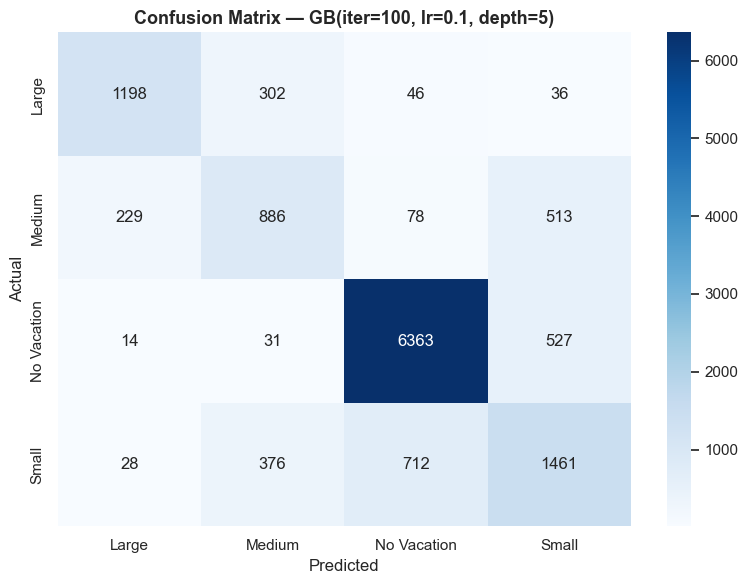


Classification Report complet:
              precision    recall  f1-score   support

       Large       0.82      0.76      0.79      1582
      Medium       0.56      0.52      0.54      1706
 No Vacation       0.88      0.92      0.90      6935
       Small       0.58      0.57      0.57      2577

    accuracy                           0.77     12800
   macro avg       0.71      0.69      0.70     12800
weighted avg       0.77      0.77      0.77     12800



In [30]:
# Confusion Matrix
best_cls_model = best_cls['model']
y_pred_best_cls = best_cls_model.predict(X_val)

fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_val_cls, y_pred_best_cls)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=le_vacation.classes_, yticklabels=le_vacation.classes_)
ax.set_title(f'Confusion Matrix — {best_cls["name"]}', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('plots/11_confusion_matrix_best.png', bbox_inches='tight')
plt.show()

print("\nClassification Report complet:")
print(classification_report(y_val_cls, y_pred_best_cls, target_names=le_vacation.classes_, zero_division=0))

---
## 5. Regresie — Prezicerea `salary`

### Funcție helper

In [31]:
def evaluate_reg(model, X_tr, y_tr, X_v, y_v, name):
    model.fit(X_tr, y_tr)
    y_pred_tr = model.predict(X_tr)
    y_pred_v = model.predict(X_v)
    r2_tr = r2_score(y_tr, y_pred_tr)
    r2_v = r2_score(y_v, y_pred_v)
    rmse_tr = np.sqrt(mean_squared_error(y_tr, y_pred_tr))
    rmse = np.sqrt(mean_squared_error(y_v, y_pred_v))
    mae = mean_absolute_error(y_v, y_pred_v)
    return {'name': name, 'r2_train': r2_tr, 'r2': r2_v, 'rmse_train': rmse_tr, 'rmse': rmse, 'mae': mae, 'model': model}

all_reg = []

### 5.1 Linear Regression (baseline)

Cel mai simplu model de regresie. Caută o formulă liniară: `salary = a₁×feature₁ + a₂×feature₂ + ... + b`

In [32]:
print("=== Linear Regression ===")
print(f"{'Model':45s} | {'R²_train':>10s} | {'R²_val':>10s} | {'RMSE':>8s} | {'MAE':>8s}")
print("-" * 100)
r = evaluate_reg(LinearRegression(), X_train, y_train_reg, X_val, y_val_reg, "Linear Regression")
all_reg.append(r)
print(f"  {r['name']:45s} | {r['r2_train']:.4f}     | {r['r2']:.4f}     | {r['rmse']:.0f}    | {r['mae']:.0f}")

=== Linear Regression ===
Model                                         |   R²_train |     R²_val |     RMSE |      MAE
----------------------------------------------------------------------------------------------------
  Linear Regression                             | 0.9476     | 0.9451     | 8688    | 6748


### 5.2 Ridge Regression (L2 regularization) — Ablație

Ridge adaugă un termen de **penalizare L2** care previne overfitting-ul.
`alpha` = puterea regularizării: alpha mic ≈ Linear Regression, alpha mare = coeficienți mai mici.

In [33]:
print("=== Ridge Regression (L2) ===")
print(f"{'Model':45s} | {'R²_train':>10s} | {'R²_val':>10s} | {'RMSE':>8s} | {'MAE':>8s}")
print("-" * 100)
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    r = evaluate_reg(Ridge(alpha=alpha), X_train, y_train_reg, X_val, y_val_reg,
                     f"Ridge(alpha={alpha})")
    all_reg.append(r)
    print(f"  {r['name']:45s} | {r['r2_train']:.4f}     | {r['r2']:.4f}     | {r['rmse']:.0f}    | {r['mae']:.0f}")

=== Ridge Regression (L2) ===
Model                                         |   R²_train |     R²_val |     RMSE |      MAE
----------------------------------------------------------------------------------------------------
  Ridge(alpha=0.01)                             | 0.9476     | 0.9451     | 8688    | 6748
  Ridge(alpha=0.1)                              | 0.9476     | 0.9451     | 8688    | 6748
  Ridge(alpha=1)                                | 0.9476     | 0.9451     | 8688    | 6748
  Ridge(alpha=10)                               | 0.9476     | 0.9451     | 8688    | 6747
  Ridge(alpha=100)                              | 0.9476     | 0.9451     | 8689    | 6745
  Ridge(alpha=1000)                             | 0.9454     | 0.9431     | 8843    | 6822


### 5.3 Lasso Regression (L1 regularization) — Ablație

Lasso adaugă un termen de **penalizare L1** care face **feature selection** automat (anulează coeficienți irelevanți).

In [34]:
print("=== Lasso Regression (L1) ===")
print(f"{'Model':45s} | {'R²_train':>10s} | {'R²_val':>10s} | {'RMSE':>8s} | {'MAE':>8s}")
print("-" * 100)
for alpha in [0.01, 0.1, 1, 10, 100]:
    r = evaluate_reg(Lasso(alpha=alpha, max_iter=5000), X_train, y_train_reg, X_val, y_val_reg,
                     f"Lasso(alpha={alpha})")
    all_reg.append(r)
    print(f"  {r['name']:45s} | {r['r2_train']:.4f}     | {r['r2']:.4f}     | {r['rmse']:.0f}    | {r['mae']:.0f}")

=== Lasso Regression (L1) ===
Model                                         |   R²_train |     R²_val |     RMSE |      MAE
----------------------------------------------------------------------------------------------------
  Lasso(alpha=0.01)                             | 0.9476     | 0.9451     | 8688    | 6748
  Lasso(alpha=0.1)                              | 0.9476     | 0.9451     | 8688    | 6748
  Lasso(alpha=1)                                | 0.9476     | 0.9451     | 8688    | 6748
  Lasso(alpha=10)                               | 0.9476     | 0.9451     | 8688    | 6747
  Lasso(alpha=100)                              | 0.9462     | 0.9439     | 8786    | 6812


### 5.6 Gradient Boosting Regressor — Ablație

Gradient Boosting pentru regresie — construiește arbori secvențial, fiecare corectând erorile anterioare.

In [37]:
print("=== Gradient Boosting Regressor ===")
print(f"{'Model':45s} | {'R²_train':>10s} | {'R²_val':>10s} | {'RMSE':>8s} | {'MAE':>8s}")
print("-" * 100)
for n_est in [100, 200, 300]:
    for lr in [0.05, 0.1]:
        r = evaluate_reg(
            HistGradientBoostingRegressor(max_iter=n_est, learning_rate=lr,
                                      max_depth=5, random_state=42),
            X_train, y_train_reg, X_val, y_val_reg,
            f"GBR(iter={n_est}, lr={lr}, depth=5)")
        all_reg.append(r)
        print(f"  {r['name']:45s} | {r['r2_train']:.4f}     | {r['r2']:.4f}     | {r['rmse']:.0f}    | {r['mae']:.0f}")

# Tune depth
print("\nTuning max_depth:")
for d in [3, 5, 7]:
    r = evaluate_reg(
        HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1,
                                  max_depth=d, random_state=42),
        X_train, y_train_reg, X_val, y_val_reg,
        f"GBR(iter=200, lr=0.1, depth={d})")
    all_reg.append(r)
    print(f"  {r['name']:45s} | {r['r2_train']:.4f}     | {r['r2']:.4f}     | {r['rmse']:.0f}    | {r['mae']:.0f}")

=== Gradient Boosting Regressor ===
Model                                         |   R²_train |     R²_val |     RMSE |      MAE
----------------------------------------------------------------------------------------------------
  GBR(iter=100, lr=0.05, depth=5)               | 0.9179     | 0.9152     | 10801    | 8105
  GBR(iter=100, lr=0.1, depth=5)                | 0.9551     | 0.9526     | 8072    | 6006
  GBR(iter=200, lr=0.05, depth=5)               | 0.9553     | 0.9526     | 8070    | 5988
  GBR(iter=200, lr=0.1, depth=5)                | 0.9717     | 0.9682     | 6613    | 5114
  GBR(iter=300, lr=0.05, depth=5)               | 0.9663     | 0.9631     | 7121    | 5405
  GBR(iter=300, lr=0.1, depth=5)                | 0.9767     | 0.9726     | 6135    | 4815

Tuning max_depth:
  GBR(iter=200, lr=0.1, depth=3)                | 0.9542     | 0.9528     | 8059    | 6011
  GBR(iter=200, lr=0.1, depth=5)                | 0.9717     | 0.9682     | 6613    | 5114
  GBR(iter=200, lr=0.

### 5.7 Tabel sumar regresie + Grafice evaluare

In [38]:
# Tabel sumar
reg_df = pd.DataFrame([{
    'Model': r['name'], 'R²_train': r['r2_train'], 'R²_val': r['r2'],
    'RMSE': r['rmse'], 'MAE': r['mae']
} for r in all_reg]).sort_values('R2_val' if 'R2_val' in ['R²_val'] else 'R²_val', ascending=False)

print("TOP 10 Regresie:")
print(reg_df.head(10).to_string(index=False, float_format='%.4f'))
reg_df.to_csv('results/regression_results.csv', index=False)

best_reg = max(all_reg, key=lambda x: x['r2'])
print(f"\n>>> BEST: {best_reg['name']} (R²={best_reg['r2']:.4f}, RMSE={best_reg['rmse']:.0f})")

TOP 10 Regresie:
                          Model  R²_train  R²_val      RMSE       MAE
 GBR(iter=200, lr=0.1, depth=7)    0.9769  0.9738 6007.0347 4732.9315
 GBR(iter=300, lr=0.1, depth=5)    0.9767  0.9726 6135.0319 4815.2389
 GBR(iter=200, lr=0.1, depth=5)    0.9717  0.9682 6612.9041 5113.6917
 GBR(iter=200, lr=0.1, depth=5)    0.9717  0.9682 6612.9041 5113.6917
GBR(iter=300, lr=0.05, depth=5)    0.9663  0.9631 7120.7560 5405.1790
 GBR(iter=200, lr=0.1, depth=3)    0.9542  0.9528 8059.4076 6011.1495
GBR(iter=200, lr=0.05, depth=5)    0.9553  0.9526 8069.8848 5988.0953
 GBR(iter=100, lr=0.1, depth=5)    0.9551  0.9526 8072.3181 6006.4144
                Lasso(alpha=10)    0.9476  0.9451 8687.8864 6747.3093
                 Lasso(alpha=1)    0.9476  0.9451 8688.1608 6747.7676

>>> BEST: GBR(iter=200, lr=0.1, depth=7) (R²=0.9738, RMSE=6007)


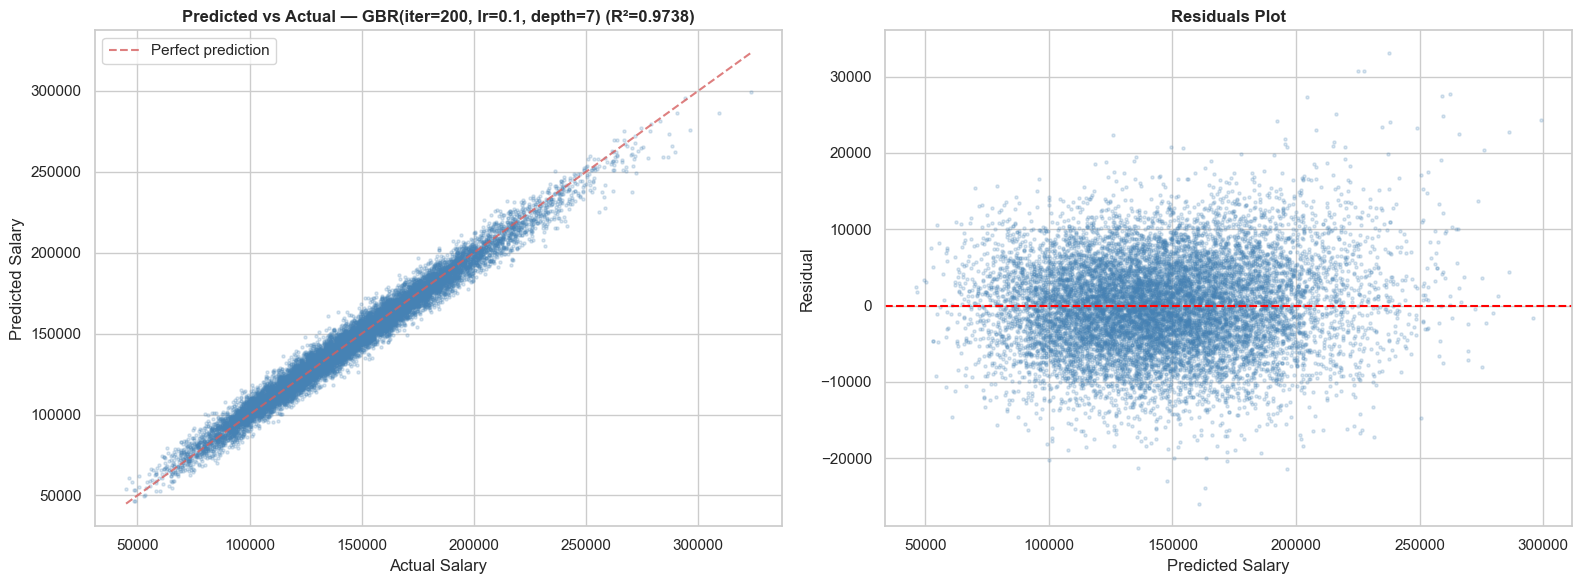

In [39]:
# Predicted vs Actual
best_reg_model = best_reg['model']
y_pred_reg_val = best_reg_model.predict(X_val)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Predicted vs Actual
axes[0].scatter(y_val_reg, y_pred_reg_val, alpha=0.2, s=5, color='steelblue')
lims = [min(y_val_reg.min(), y_pred_reg_val.min()), max(y_val_reg.max(), y_pred_reg_val.max())]
axes[0].plot(lims, lims, 'r--', alpha=0.8, label='Perfect prediction')
axes[0].set_xlabel('Actual Salary')
axes[0].set_ylabel('Predicted Salary')
axes[0].set_title(f'Predicted vs Actual — {best_reg["name"]} (R²={best_reg["r2"]:.4f})',
                  fontsize=12, fontweight='bold')
axes[0].legend()

# Residuals
residuals = y_val_reg - y_pred_reg_val
axes[1].scatter(y_pred_reg_val, residuals, alpha=0.2, s=5, color='steelblue')
axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Salary')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residuals Plot', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/12_predicted_vs_actual_salary.png', bbox_inches='tight')
plt.show()

### 5.8 Comportament comparativ pe setul de antrenare versus cel de validare


--- Generare curbe train vs val (Line Plots) ---


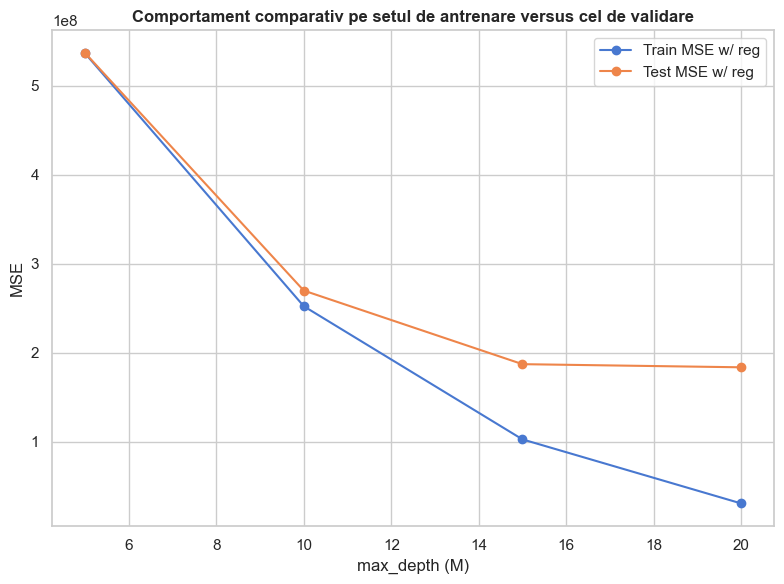

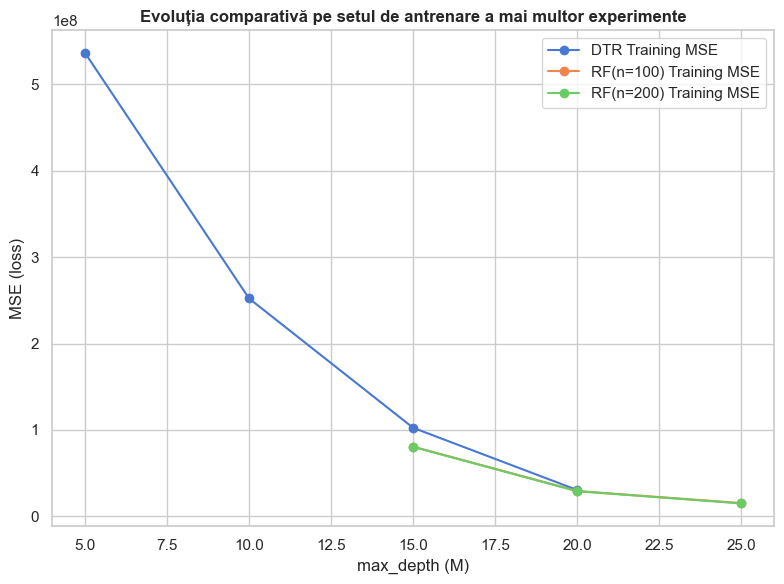

In [40]:
# Overfitting Check (Train vs Val)
print("\n--- Generare curbe train vs val (Line Plots) ---")
dtr_res = [r for r in all_reg if r['name'].startswith('DTR(depth=')]
depths = [int(r['name'].split('=')[1].replace(')', '')) for r in dtr_res]
mse_train = [r['rmse_train']**2 for r in dtr_res]
mse_val = [r['rmse']**2 for r in dtr_res]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(depths, mse_train, label='Train MSE w/ reg', marker='o')
ax.plot(depths, mse_val, label='Test MSE w/ reg', marker='o')
ax.set_xlabel('max_depth (M)')
ax.set_ylabel('MSE')
ax.set_title('Comportament comparativ pe setul de antrenare versus cel de validare', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('plots/14_overfitting_curve.png', bbox_inches='tight')
plt.show()

# Comparative Training
rf100_res = [r for r in all_reg if r['name'].startswith('RFR(n=100')]
rf200_res = [r for r in all_reg if r['name'].startswith('RFR(n=200')]
d_rf100 = [int(r['name'].split('depth=')[1].replace(')', '')) for r in rf100_res]
mse_tr100 = [r['rmse_train']**2 for r in rf100_res]
d_rf200 = [int(r['name'].split('depth=')[1].replace(')', '')) for r in rf200_res]
mse_tr200 = [r['rmse_train']**2 for r in rf200_res]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(depths, mse_train, label='DTR Training MSE', marker='o')
ax.plot(d_rf100, mse_tr100, label='RF(n=100) Training MSE', marker='o')
ax.plot(d_rf200, mse_tr200, label='RF(n=200) Training MSE', marker='o')
ax.set_xlabel('max_depth (M)')
ax.set_ylabel('MSE (loss)')
ax.set_title('Evoluția comparativă pe setul de antrenare a mai multor experimente', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('plots/15_comparative_training.png', bbox_inches='tight')
plt.show()

---
## 6. Predicții pe setul de test

In [41]:
# Clasificare
test_vacation_pred = best_cls_model.predict(X_test_final)
test_vacation_labels = le_vacation.inverse_transform(test_vacation_pred)

# Regresie
test_salary_pred = best_reg_model.predict(X_test_final)

# Salvare
predictions_df = pd.DataFrame({
    'vacation_predicted': test_vacation_labels,
    'salary_predicted': test_salary_pred
})
predictions_df.to_csv('results/test_predictions.csv', index=False)

print("Predicții salvate în results/test_predictions.csv")
print(f"\nDistribuția vacation pe test:")
print(pd.Series(test_vacation_labels).value_counts())
print(f"\nSalary pe test: Mean={test_salary_pred.mean():.0f}, Std={test_salary_pred.std():.0f}")

Predicții salvate în results/test_predictions.csv

Distribuția vacation pe test:
No Vacation    9011
Small          3163
Medium         2004
Large          1822
Name: count, dtype: int64

Salary pe test: Mean=145578, Std=36354


---
## 7. Sumar final

In [42]:
print("=" * 70)
print("SUMAR FINAL")
print("=" * 70)
print(f"""
CLASIFICARE (vacation):
  Best: {best_cls['name']}
  F1-Score = {best_cls['f1']:.4f}
  Accuracy = {best_cls['acc']:.4f}
  Precision = {best_cls['prec']:.4f}

REGRESIE (salary):
  Best: {best_reg['name']}
  R² = {best_reg['r2']:.4f}
  RMSE = {best_reg['rmse']:.0f}
  MAE = {best_reg['mae']:.0f}

Fișiere generate:
  - plots/ (13+ grafice EDA + evaluare)
  - results/classification_results.csv
  - results/regression_results.csv
  - results/test_predictions.csv
""")

SUMAR FINAL

CLASIFICARE (vacation):
  Best: GB(iter=100, lr=0.1, depth=5)
  F1-Score = 0.7715
  Accuracy = 0.7741
  Precision = 0.7696

REGRESIE (salary):
  Best: GBR(iter=200, lr=0.1, depth=7)
  R² = 0.9738
  RMSE = 6007
  MAE = 4733

Fișiere generate:
  - plots/ (13+ grafice EDA + evaluare)
  - results/classification_results.csv
  - results/regression_results.csv
  - results/test_predictions.csv

